# Individual results: the life periods of Chinese and European individuals

In [1]:
import json
import sys

import duckdb
import matplotlib.pyplot as plt
import polars as pl
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely import STRtree, points
from shapely.geometry import shape

sys.path.insert(0, '../../../notebooks/notebooks_analysis')
from style import *

DB_PATH = '../../../data/cultura/cultura_database_V4.duckdb'  # read only
ACTIVE_LIFE_PATH = '../../../data/enriched_parquets/individual_active_life.parquet'  # 03_b_active_life, not yet in the database
BIRTH_YEARS = (700, 799)  # one century of birth
MIN_AGE_AT_DEATH = 15  # years: younger deaths are left out
COUNTRIES_PATH = '../../../data/ne_110m_admin_0_countries.geojson'  # Natural Earth present-day borders
REGIONS = {'China': lambda country: country['ISO_A3'] == 'CHN', 'Europe': lambda country: country['CONTINENT'] == 'Europe'}
PER_CASE = {('wikidata', 'wikidata'): 2, ('estimated', 'wikidata'): 2, ('wikidata', 'estimated'): 1}  # individuals shown per region and (birth, death) source
PERIOD_COLORS = {'Before the active life': ORANGE, 'Active life': BLUE, 'After the active life': GREEN}
END_COLORS = {'Active life ends before death': GREEN, 'Active life ends at death': LIGHT_GREY, 'Active life ends after death': RED}

apply_style()

## Data
Individuals born in the century whose Wikidata citizenship (P27) is a polity located, by its Wikidata coordinates, in present-day China or in a present-day European state (Natural Earth borders); citizenships in both regions are left out. Birthplaces are too rare in these centuries (777 of the 15,880 individuals born 700–799). Before the active life = birth → start of the active life, active life = start → end (the earliest and the latest dated work or position, else estimated; 03_b_active_life), after = end → death.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
people = con.sql('''
    WITH citizenship AS (
        SELECT entity.qid AS qid, unnest(country_of_citizenship).entity.qid AS polity_qid
        FROM   individual
    )
    SELECT DISTINCT individual_enriched.entity.qid AS qid,
           individual_enriched.entity.label_en AS name,
           place.coordinates.longitude AS longitude,
           place.coordinates.latitude AS latitude,
           len(individual.sitelink)  AS sitelinks,
           individual_enriched.birth_date.year        AS birth_year,
           individual_enriched.birth_date.source      AS birth_source,
           individual_enriched.death_date.year        AS death_year,
           individual_enriched.death_date.source      AS death_source,
           active_life.start_of_active_life.year   AS peak_start,
           active_life.end_of_active_life.year     AS peak_end,
           active_life.start_of_active_life.source AS peak_source,
           individual_enriched.birth_date.cohort      AS birth_cohort,
           individual_enriched.death_date.cohort      AS death_cohort,
           active_life.start_of_active_life.cohort AS start_cohort,
           active_life.end_of_active_life.cohort   AS end_cohort
    FROM   individual_enriched
    JOIN   individual ON individual.entity.qid = individual_enriched.entity.qid
    JOIN   read_parquet($active_life) AS active_life ON active_life.qid = individual_enriched.entity.qid
    JOIN   citizenship ON citizenship.qid = individual_enriched.entity.qid
    JOIN   place ON place.entity.qid = citizenship.polity_qid
    WHERE  individual_enriched.birth_date.year BETWEEN $first AND $last AND individual_enriched.death_date.year IS NOT NULL
           AND active_life.start_of_active_life.year IS NOT NULL AND place.coordinates.longitude IS NOT NULL
''', params={'first': BIRTH_YEARS[0], 'last': BIRTH_YEARS[1], 'active_life': ACTIVE_LIFE_PATH}).pl()

everyone = con.sql('''
    SELECT CASE WHEN active_life.end_of_active_life.year < individual_enriched.death_date.year THEN 'Active life ends before death'
                WHEN active_life.end_of_active_life.year = individual_enriched.death_date.year THEN 'Active life ends at death'
                ELSE 'Active life ends after death' END AS peak_end_vs_death,
           count(*) AS individuals
    FROM   individual_enriched
    JOIN   read_parquet($active_life) AS active_life ON active_life.qid = individual_enriched.entity.qid
    WHERE  individual_enriched.death_date.year IS NOT NULL AND active_life.end_of_active_life.year IS NOT NULL
    GROUP BY ALL
''', params={'active_life': ACTIVE_LIFE_PATH}).pl().with_columns(pl.lit('All individuals').alias('group'))

countries = json.load(open(COUNTRIES_PATH))['features']
region_shapes = [(region, shape(country['geometry'])) for country in countries for region, inside in REGIONS.items() if inside(country['properties'])]
tree = STRtree([geometry for _, geometry in region_shapes])
spot, shape_index = tree.query(points(people['longitude'].to_numpy(), people['latitude'].to_numpy()), predicate='within')
people = (
    people[spot].with_columns(pl.Series('region', [region_shapes[i][0] for i in shape_index]))
    .drop('longitude', 'latitude').unique()
    .filter(pl.len().over('qid') == 1)
)
con.close()
assert people['qid'].n_unique() == people.height
print(f'{people.height:,} individuals born {BIRTH_YEARS[0]}–{BIRTH_YEARS[1]} with a birth, a death and an active life')
people.group_by('region', 'birth_source', 'death_source').len().sort('region', 'len', descending=[False, True])

12,336 individuals born 700–799 with a birth, a death and an active life


region,birth_source,death_source,len
str,str,str,u32
"""China""","""estimated""","""wikidata""",10038
"""China""","""wikidata""","""wikidata""",1994
"""China""","""wikidata""","""estimated""",48
"""Europe""","""estimated""","""wikidata""",131
"""Europe""","""wikidata""","""wikidata""",106
"""Europe""","""wikidata""","""estimated""",19


## Individuals shown
In each region, the most-linked individuals (Wikipedia pages) of each case: both dates from Wikidata, an estimated birth, an estimated death; named, dead at 15 or older.

In [3]:
shown = pl.concat([
    people.filter((pl.col('region') == region) & (pl.col('birth_source') == birth) & (pl.col('death_source') == death)
                  & pl.col('name').is_not_null() & (pl.col('death_year') - pl.col('birth_year') >= MIN_AGE_AT_DEATH))
    .sort('sitelinks', descending=True).head(n)
    for region in REGIONS for (birth, death), n in PER_CASE.items()
])
assert shown.height == len(REGIONS) * sum(PER_CASE.values())
shown

qid,name,sitelinks,birth_year,birth_source,death_year,death_source,peak_start,peak_end,peak_source,birth_cohort,death_cohort,start_cohort,end_cohort,region
str,str,i64,i64,str,i64,str,i64,i64,str,struct[4],struct[4],struct[4],struct[4],str
"""Q7071""","""Li Bai""",191,701,"""wikidata""",762,"""wikidata""",738,758,"""estimated""",null,null,"{""Culture"",700,25,37.0}","{""Culture"",700,25,57.0}","""China"""
"""Q33772""","""Du Fu""",136,712,"""wikidata""",770,"""wikidata""",749,769,"""estimated""",null,null,"{""Culture"",700,25,37.0}","{""Culture"",700,25,57.0}","""China"""
"""Q326950""","""Linji Yixuan""",27,793,"""estimated""",867,"""wikidata""",840,859,"""estimated""","{""Discovery/Science"",700,236,74.199153}",null,"{""Discovery/Science"",700,11,47.0}","{""Discovery/Science"",700,11,66.0}","""China"""
"""Q1632823""","""Huangbo Xiyun""",16,781,"""estimated""",855,"""wikidata""",828,847,"""estimated""","{""Discovery/Science"",700,236,74.199153}",null,"{""Discovery/Science"",700,11,47.0}","{""Discovery/Science"",700,11,66.0}","""China"""
"""Q971072""","""Han Xiang""",16,794,"""wikidata""",868,"""estimated""",841,860,"""estimated""",null,"{""Discovery/Science"",700,236,74.199153}","{""Discovery/Science"",700,11,47.0}","{""Discovery/Science"",700,11,66.0}","""China"""
"""Q3044""","""Charlemagne""",184,748,"""wikidata""",814,"""wikidata""",768,814,"""dated works and positions""",null,null,null,null,"""Europe"""
"""Q132086""","""Leo III""",85,750,"""wikidata""",816,"""wikidata""",796,816,"""dated works and positions""",null,null,null,null,"""Europe"""
"""Q233573""","""Offa of Mercia""",49,737,"""estimated""",796,"""wikidata""",757,796,"""dated works and positions""","{""Leadership"",700,540,58.501852}",null,null,null,"""Europe"""
"""Q272326""","""Æthelwulf""",48,799,"""estimated""",858,"""wikidata""",839,858,"""dated works and positions""","{""Leadership"",700,540,58.501852}",null,null,null,"""Europe"""


## Figure: before, during and after the active life of Chinese and European individuals born in the 8th century

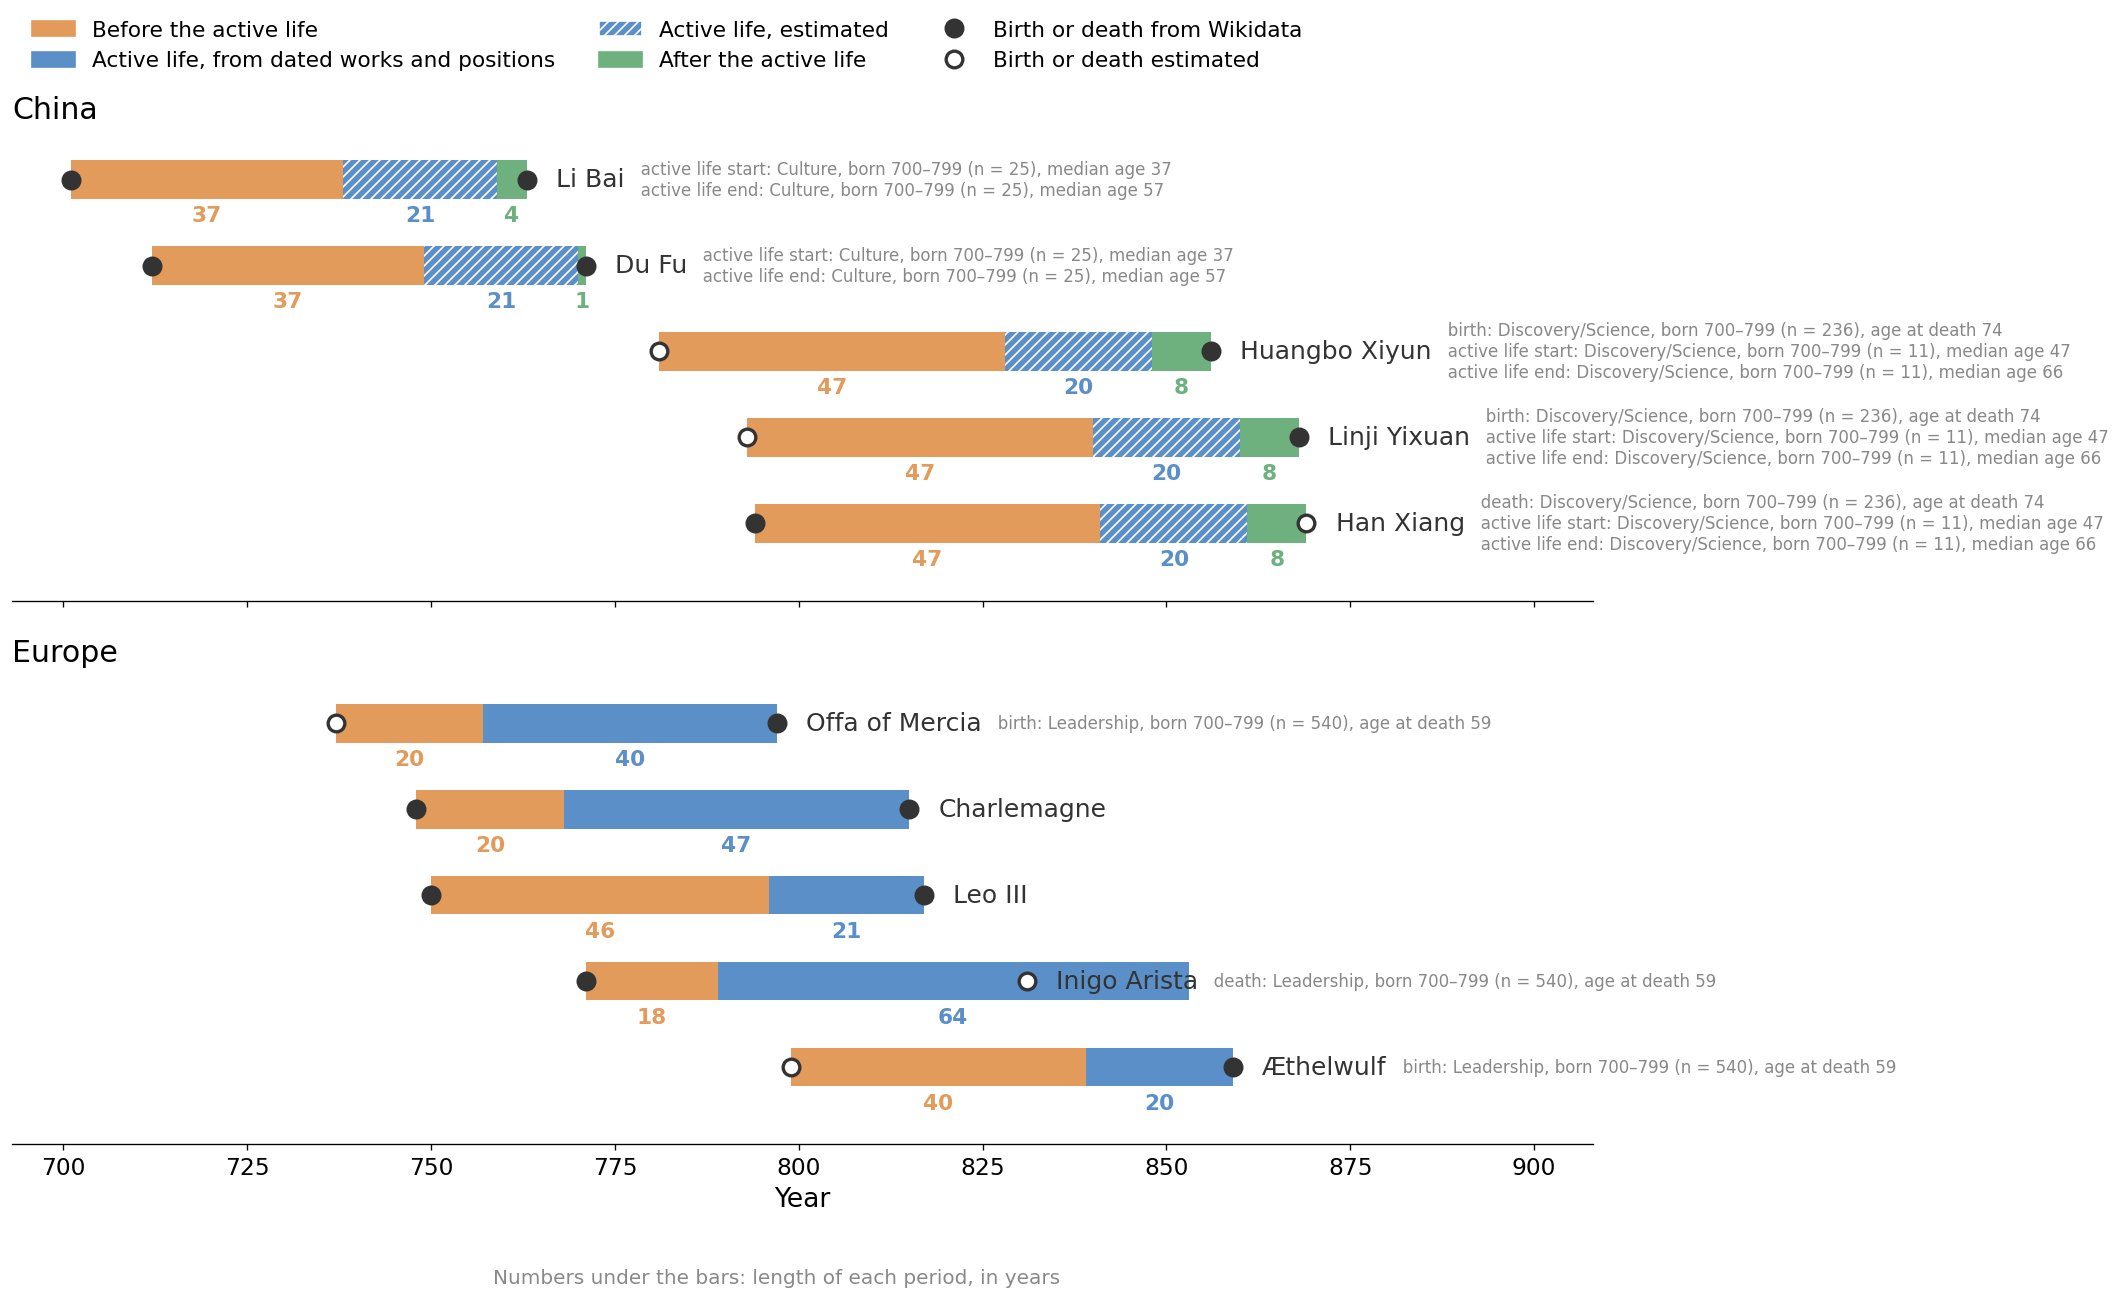

In [4]:
def draw_person(ax, row, person):
    periods = [
        ('Before the active life', person['birth_year'], person['peak_start']),
        ('Active life', person['peak_start'], person['peak_end'] + 1),
        ('After the active life', person['peak_end'] + 1, person['death_year'] + 1),
    ]
    for period, start, end in periods:
        if end > start:
            estimated = period == 'Active life' and person['peak_source'] == 'estimated'
            ax.barh(row, end - start, left=start, height=0.45, color=PERIOD_COLORS[period], hatch='////' if estimated else None, edgecolor='white', linewidth=0)
            ax.text((start + end) / 2, row - 0.3, end - start, ha='center', va='top', fontsize=13, color=PERIOD_COLORS[period], fontweight='bold')
    for year, source in [(person['birth_year'], person['birth_source']), (person['death_year'] + 1, person['death_source'])]:
        ax.plot(year, row, 'o', markersize=10, markeredgewidth=2, color=TEXT, markerfacecolor='white' if source == 'estimated' else TEXT, zorder=3)
    name = ax.text(person['death_year'] + 5, row, person['name'], va='center', fontsize=15, color=TEXT)
    ax.annotate(cohort_text(person), xycoords=name, xy=(1, 0.5), va='center', fontsize=10, color=MUTED_TEXT)


def cohort_text(person):
    def one(label, cohort, age):
        occupation = cohort['occupation'] or 'all occupations'
        born = f", born {cohort['century']}–{cohort['century'] + 99}" if cohort['century'] is not None else ''
        return f"{label}: {occupation}{born} (n = {cohort['individuals']:,}), {age} {cohort['age']:.0f}"
    parts = []
    if person['birth_cohort']:
        parts.append(one('birth', person['birth_cohort'], 'age at death'))
    if person['death_cohort']:
        parts.append(one('death', person['death_cohort'], 'age at death'))
    if person['start_cohort']:
        parts.append(one('active life start', person['start_cohort'], 'median age'))
    if person['end_cohort']:
        parts.append(one('active life end', person['end_cohort'], 'median age'))
    return '   ' + '\n   '.join(parts)


fig, axes = plt.subplots(len(REGIONS), 1, figsize=(17, 11), sharex=True, gridspec_kw={'hspace': 0.15})
for ax, region in zip(axes, REGIONS):
    group = shown.filter(pl.col('region') == region).sort('birth_year', descending=True)
    for row, person in enumerate(group.iter_rows(named=True)):
        draw_person(ax, row, person)
    ax.set_title(region, loc='left', fontsize=18, color='black')
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.set_ylim(-0.9, group.height - 0.4)
axes[-1].set_xlim(shown['birth_year'].min() - 8, shown['death_year'].max() + 40)
for ax in axes:
    ax.spines['bottom'].set_bounds(shown['birth_year'].min() - 8, shown['death_year'].max() + 40)
axes[-1].set_xlabel('Year')
axes[0].legend(handles=[
    Patch(color=PERIOD_COLORS['Before the active life'], label='Before the active life'),
    Patch(color=PERIOD_COLORS['Active life'], label='Active life, from dated works and positions'),
    Patch(facecolor=PERIOD_COLORS['Active life'], hatch='////', edgecolor='white', label='Active life, estimated'),
    Patch(color=PERIOD_COLORS['After the active life'], label='After the active life'),
    Line2D([], [], marker='o', linestyle='', markersize=10, markeredgewidth=2, color=TEXT, label='Birth or death from Wikidata'),
    Line2D([], [], marker='o', linestyle='', markersize=10, markeredgewidth=2, color=TEXT, markerfacecolor='white', label='Birth or death estimated'),
], loc='lower left', bbox_to_anchor=(0, 1.08), ncol=3, fontsize=13)
fig.text(0.5, 0.005, 'Numbers under the bars: length of each period, in years', ha='center', fontsize=12, color=MUTED_TEXT)
plt.show()

## Figure: end of the active life and death

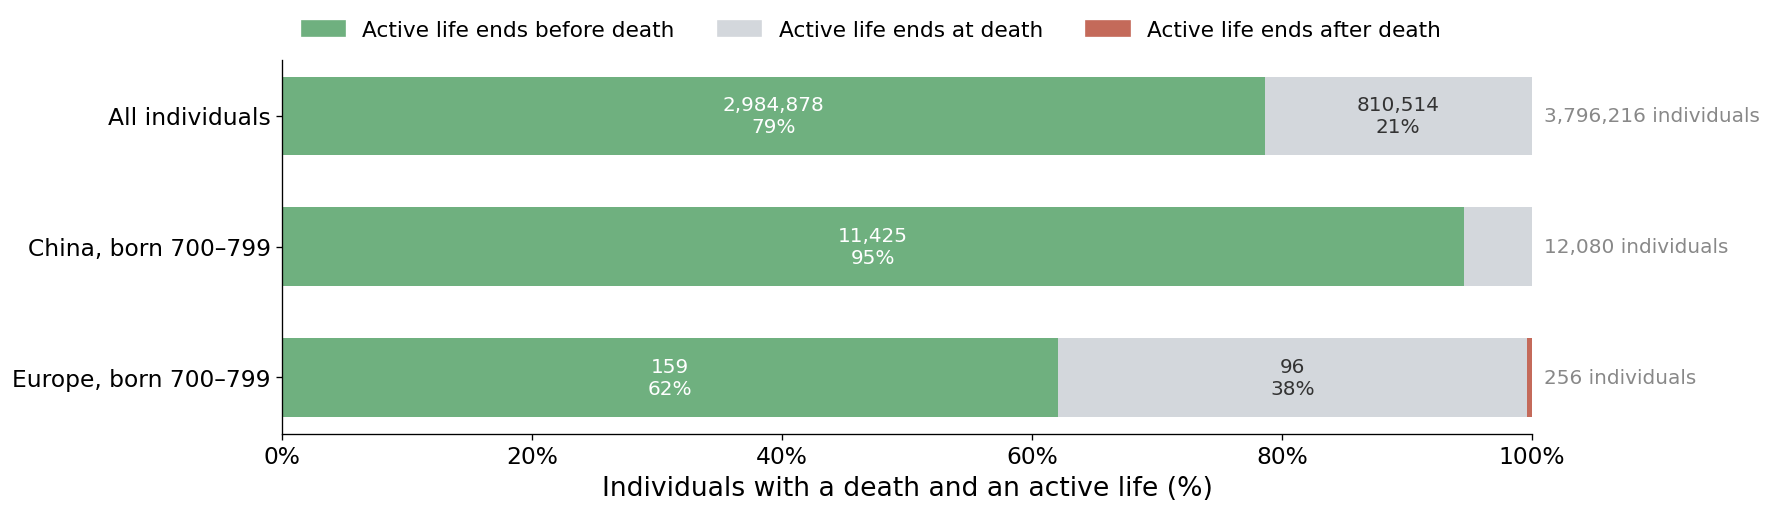

In [5]:
by_region = (
    people.with_columns(
        pl.when(pl.col('peak_end') < pl.col('death_year')).then(pl.lit('Active life ends before death'))
        .when(pl.col('peak_end') == pl.col('death_year')).then(pl.lit('Active life ends at death'))
        .otherwise(pl.lit('Active life ends after death')).alias('peak_end_vs_death'),
        pl.format('{}, born {}–{}', 'region', pl.lit(BIRTH_YEARS[0]), pl.lit(BIRTH_YEARS[1])).alias('group'),
    )
    .group_by('group', 'peak_end_vs_death').agg(pl.len().cast(pl.Int64).alias('individuals'))
)
ends = pl.concat([by_region, everyone.select(by_region.columns)])
groups = ['All individuals', *[f'{region}, born {BIRTH_YEARS[0]}–{BIRTH_YEARS[1]}' for region in REGIONS]]

fig, ax = plt.subplots(figsize=(15, 4.5))
for row, group in enumerate(groups[::-1]):
    counts = ends.filter(pl.col('group') == group)
    total = counts['individuals'].sum()
    left = 0
    for end, color in END_COLORS.items():
        n = counts.filter(pl.col('peak_end_vs_death') == end)['individuals'].sum()
        share = 100 * n / total
        ax.barh(row, share, left=left, height=0.6, color=color)
        if share >= 6:
            ax.text(left + share / 2, row, f'{n:,}\n{share:.0f}%', ha='center', va='center', fontsize=12, color=text_color_on(color))
        left += share
    ax.text(101, row, f'{total:,} individuals', va='center', fontsize=12, color=MUTED_TEXT)
ax.set_yticks(range(len(groups)))
ax.set_yticklabels(groups[::-1])
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PERCENT)
ax.set_xlabel('Individuals with a death and an active life (%)')
ax.legend(handles=[Patch(color=color, label=end) for end, color in END_COLORS.items()], loc='lower left', bbox_to_anchor=(0, 1), ncol=3)
plt.tight_layout()
plt.show()